# 4. Preprocesamiento y modelado con PySpark

Secciones 3.2 (PySpark) y 4.3 del enunciado.

**Reglas obligatorias respetadas en este notebook**

* Se lee el CSV completo con `SparkSession`; los datos permanecen como DataFrame de Spark.
* No se usa `.toPandas()` ni `.collect()` sobre el dataset. Solo se traen al driver
  (a) tablas agregadas de pocas filas (conteos de categorías, matriz de confusión) y
  (b) al final, las columnas `id`, `default` y `score` del conjunto de prueba, cuyo tiempo de
  transferencia se reporta por separado.
* La partición común se lee del Parquet generado en el notebook 02 y se filtra por `split`
  (no se usa `randomSplit`).
* `StringIndexer`, `OneHotEncoder`, `Imputer`, `VectorAssembler` y `StandardScaler` se ajustan solo
  con train.
* El DataFrame resultante del `VectorAssembler` se cachea con `persist(MEMORY_AND_DISK)`
  antes de entrenar.
* Búsqueda de hiperparámetros exclusivamente con `ParamGridBuilder` + `CrossValidator`
  (`numFolds=3`) y `BinaryClassificationEvaluator(metricName="areaUnderROC")`.

In [1]:
import sys  # Permite modificar la ruta de búsqueda de módulos
sys.path.insert(0, "..")  # Agrega la raíz del proyecto
import time  # Medición de tiempos con time.time()
import numpy as np  # Cálculo numérico (solo sobre resultados pequeños)
import pandas as pd  # Tablas de resultados (solo resultados pequeños)
import matplotlib.pyplot as plt  # Gráficos
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay  # Curva ROC y gráfico de la matriz de confusión (sobre id/default/score)
from pyspark import StorageLevel  # Nivel de persistencia en memoria y disco
from pyspark.sql import functions as F  # Funciones de columnas de Spark
from pyspark.ml.functions import vector_to_array  # Convierte vectores de Spark en arreglos
from pyspark.ml.classification import (  # Los seis clasificadores de pyspark.ml
    LogisticRegression, DecisionTreeClassifier, RandomForestClassifier,  # Lineal y árboles
    GBTClassifier, LinearSVC, NaiveBayes,  # Boosting, SVM y Naive Bayes
)
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator  # Búsqueda de hiperparámetros
from pyspark.ml.evaluation import BinaryClassificationEvaluator  # Evaluador AUC ROC
from src import config as cfg  # Configuración central
from src import preparacion_spark as prep_sp  # Preparación con Spark
from src.utilidades import actualizar_json, guardar_json, guardar_figura, info_hardware  # Utilidades

hardware = info_hardware()  # Información del equipo
hardware  # Declaración del hardware

{'sistema': 'Windows 10',
 'procesador': 'AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD',
 'nucleos_fisicos': 6,
 'nucleos_logicos': 12,
 'ram_total_gb': 13.8,
 'ram_disponible_gb': 6.1,
 'python': '3.9.25'}

## Sesión de Spark

Se usa la configuración del enunciado (`memory.fraction` 0.8, `storageFraction` 0.3) en
modo local, con **tres cambios justificados** ("u otros equivalentes debidamente
justificados", sección 4.3):

1. `spark.sql.shuffle.partitions` y `spark.default.parallelism` = **6** (una partición por
   hilo) en vez de 400. El valor 400 está pensado para un clúster con cientos de núcleos; en
   una máquina de 12 hilos cada nivel de cada árbol (RF, GBT) lanza 400 tareas diminutas y el
   costo de planificarlas domina el cálculo. En una prueba preliminar con los mismos datos,
   10 iteraciones de `GBTClassifier` tardaron 21,4 s con 400 particiones, 9,8 s con 48 y 8,7 s
   con 12; 20 árboles de `RandomForestClassifier`, 25,3 s, 5,8 s y 4,4 s. Además, cada
   partición acumula las estadísticas de los nodos en construcción (hasta `maxMemoryInMB` =
   256 MB) y luego se combinan entre particiones.
2. **`local[6]`** (un hilo por núcleo físico) en vez de los 12 hilos lógicos. En cada nivel,
   Spark envía a *cada tarea* una copia serializada de todos los árboles en construcción; con
   100 árboles de profundidad 15 (≈ 1,4 millones de nodos) y 12 tareas simultáneas la JVM se
   quedó sin memoria en tres ejecuciones sobre el dataset completo (con 48 y con 12
   particiones). Con 6 hilos ese mismo bosque se entrenó sin problemas (524 s). Los hilos
   lógicos adicionales (SMT) aportan poco en cálculo numérico intensivo.
3. `spark.driver.memory` = `spark.executor.memory` = **9g** (1 GB más que el enunciado como
   margen). En modo local el driver y el ejecutor son el mismo proceso; el equipo tiene 14 GB.

Consecuencia para la comparación de tiempos: scikit-learn usa 12 hilos (`n_jobs=-1`) y
PySpark 6, lo que se tiene en cuenta en la reflexión final.

El notebook 07 cuantifica el efecto de las particiones y de la caché sobre el dataset completo.

In [2]:
spark = prep_sp.crear_sesion(memoria=cfg.MEMORIA_SPARK, particiones=cfg.PARTICIONES_SPARK)  # Crea la sesión (local[6], 6 particiones, 9g; ver justificación)
conf = spark.sparkContext.getConf()  # Configuración efectiva de la sesión
{k: conf.get(k) for k in ["spark.master", "spark.sql.shuffle.partitions", "spark.default.parallelism", "spark.driver.memory",  # Parámetros relevantes
                          "spark.executor.memory", "spark.memory.fraction", "spark.memory.storageFraction"]}  # Se muestran para el informe

{'spark.master': 'local[6]',
 'spark.sql.shuffle.partitions': '6',
 'spark.default.parallelism': '6',
 'spark.driver.memory': '9g',
 'spark.executor.memory': '9g',
 'spark.memory.fraction': '0.8',
 'spark.memory.storageFraction': '0.3'}

## Preprocesamiento

El archivo `.gz` **no es divisible**, así que Spark lo lee en una única partición. Para
aprovechar los 6 hilos, los datos se reparticionan explícitamente en las mismas
6 particiones (≈ 180 mil filas de train cada una), de modo que cada pasada de los
algoritmos iterativos mantiene ocupados todos los hilos con la mínima sobrecarga.

In [3]:
N_PARTICIONES = cfg.PARTICIONES_SPARK  # 6 particiones de datos, una por hilo (ver justificación)
tiempos_prep = {}  # Tiempos de cada etapa del preprocesamiento
t0 = time.time()  # Inicio del preprocesamiento
df = prep_sp.construir_variables(prep_sp.leer_csv(spark))  # Lee el CSV completo y construye las variables (perezoso)
particion = spark.read.parquet(str(cfg.RUTA_PARTICION))  # Lee la partición común (id, split)
df = df.join(F.broadcast(particion), on=cfg.COL_ID, how="inner")  # Asocia cada préstamo con su split (la tabla pequeña se difunde)
df = prep_sp.transformar_numericas(df)  # log1p e indicador de nulo (deterministas)
df = df.repartition(N_PARTICIONES).persist(StorageLevel.MEMORY_AND_DISK)  # Reparte en 6 particiones y guarda en caché
n_total = df.count()  # Acción que materializa lectura + construcción + unión
tiempos_prep["lectura_y_construccion"] = time.time() - t0  # Tiempo de esta etapa
train_raw = df.filter(F.col("split") == "train")  # Conjunto de entrenamiento (filtro por split)
test_raw = df.filter(F.col("split") == "test")  # Conjunto de prueba (filtro por split)
print(f"Filas: {n_total:,}")  # Total de filas con desenlace final

Filas: 1,345,310


In [4]:
t0 = time.time()  # Inicio del ajuste de transformadores
frecuentes = prep_sp.categorias_frecuentes(train_raw, cfg.CATEGORICAS_MODELO)  # Categorías frecuentes aprendidas solo con train
train_c = prep_sp.agrupar_categorias(train_raw, frecuentes)  # Agrupa categorías raras en train
test_c = prep_sp.agrupar_categorias(test_raw, frecuentes)  # Aplica la misma agrupación a test
modelo_prep = prep_sp.pipeline_preprocesamiento().fit(train_c)  # Ajusta Imputer, StandardScaler, StringIndexer y OneHotEncoder solo con train
columnas = [cfg.COL_ID, cfg.COL_TARGET, "features"]  # Columnas necesarias para modelar
train = modelo_prep.transform(train_c).select(*columnas).persist(StorageLevel.MEMORY_AND_DISK)  # Train transformado y cacheado (tras el VectorAssembler)
test = modelo_prep.transform(test_c).select(*columnas).persist(StorageLevel.MEMORY_AND_DISK)  # Test transformado y cacheado
n_train, n_test = train.count(), test.count()  # Acciones que materializan la caché
df.unpersist()  # Libera la caché intermedia
tiempos_prep["ajuste_y_transformacion"] = time.time() - t0  # Tiempo de esta etapa
tiempos_prep["total"] = sum(tiempos_prep.values())  # Tiempo total de preprocesamiento
actualizar_json(cfg.RUTA_TIEMPOS_PREP, "pyspark", tiempos_prep)  # Guarda los tiempos para la comparación final
print(f"train: {n_train:,}  test: {n_test:,}  particiones train: {train.rdd.getNumPartitions()}")  # Tamaños y particiones
print({k: round(v, 1) for k, v in tiempos_prep.items()})  # Tiempos en segundos
print("Categorías conservadas:", frecuentes)  # Categorías tras agrupar raras

train: 1,076,248  test: 269,062  particiones train: 6
{'lectura_y_construccion': 25.0, 'ajuste_y_transformacion': 13.2, 'total': 38.2}
Categorías conservadas: {'grade': ['A', 'B', 'C', 'D', 'E', 'F'], 'home_ownership': ['MORTGAGE', 'OWN', 'RENT'], 'verification_status': ['Not Verified', 'Source Verified', 'Verified'], 'purpose': ['car', 'credit_card', 'debt_consolidation', 'home_improvement', 'major_purchase', 'medical', 'other', 'small_business'], 'addr_state': ['AL', 'AZ', 'CA', 'CO', 'CT', 'FL', 'GA', 'IL', 'IN', 'LA', 'MA', 'MD', 'MI', 'MN', 'MO', 'NC', 'NJ', 'NV', 'NY', 'OH', 'OR', 'PA', 'SC', 'TN', 'TX', 'VA', 'WA', 'WI'], 'initial_list_status': ['f', 'w'], 'application_type': ['Individual', 'Joint App']}


In [5]:
dim = train.select("features").first()[0].size  # Dimensión del vector de características (una sola fila)
print("Dimensión de 'features':", dim)  # Spark tiene una columna más por categórica que sklearn: StringIndexer(handleInvalid="keep") reserva un índice para categorías no vistas
train.groupBy(cfg.COL_TARGET).count().orderBy(cfg.COL_TARGET).show()  # Distribución de clases en train (tabla agregada)

Dimensión de 'features': 84


+-------+------+
|default| count|
+-------+------+
|      0|861401|
|      1|214847|
+-------+------+



## Modelos, espacios de búsqueda y validación cruzada

* Regresión logística y LinearSVC: `regParam` ∈ {1e-6, 1e-5, 1e-4}, L2 (`elasticNetParam=0`).
* Árboles: `maxBins = 32` (valor por defecto, se reporta). Cada variable continua se
  discretiza en ≤ 32 intervalos por cuantiles aproximados, mientras scikit-learn evalúa
  todos los cortes exactos (o 255 intervalos en `HistGradientBoosting`).
* `GBTClassifier` con `stepSize = 0.1`. `NaiveBayes(modelType="gaussian")` sin búsqueda.
* `BinaryClassificationEvaluator(metricName="areaUnderROC")` se aplica sobre la columna
  `probability` (segundo elemento = P(default)) en todos los modelos salvo LinearSVC, que solo
  ofrece `rawPrediction` (margen). **Motivo:** en los árboles de Spark `rawPrediction` contiene los
  *conteos* de cada clase en la hoja (no proporciones) y en Naive Bayes log-probabilidades
  conjuntas; ordenar por su segundo elemento no equivale a ordenar por riesgo y produce AUC
  erróneos (en una prueba preliminar, 0.35 para un árbol cuyo AUC real era 0.65).
* `CrossValidator(numFolds=3, parallelism=3)`: se evalúan 3 combinaciones a la vez con hilos
  del driver; no cambia los resultados, solo aprovecha mejor los núcleos. En RandomForest y
  GBT se usa `parallelism=1`: con 3 bosques de 100 árboles de profundidad 15 a la vez la JVM
  (8 GB) se quedó sin memoria en una primera ejecución. Por el mismo motivo solo se conserva
  vivo el mejor modelo probabilístico (el que se explica con LIME al final).

In [6]:
def evaluador_para(nombre):  # Evaluador AUC ROC con la columna de puntuación adecuada a cada modelo
    """En árboles, rawPrediction guarda CONTEOS de clase por hoja y en NaiveBayes log-probabilidades conjuntas;
    ninguno es monótono con P(default), así que se evalúa sobre 'probability'. LinearSVC solo tiene rawPrediction (margen)."""
    columna = "rawPrediction" if nombre == "LinearSVC" else "probability"  # Columna con la puntuación ordenable
    return BinaryClassificationEvaluator(labelCol=cfg.COL_TARGET, rawPredictionCol=columna, metricName="areaUnderROC")  # AUC ROC

comunes = dict(featuresCol="features", labelCol=cfg.COL_TARGET)  # Parámetros comunes a todos los modelos
lr = LogisticRegression(elasticNetParam=0.0, maxIter=100, **comunes)  # Regresión logística L2
dt = DecisionTreeClassifier(maxBins=cfg.MAX_BINS_SPARK, seed=cfg.SEMILLA, **comunes)  # Árbol de decisión
rf = RandomForestClassifier(maxBins=cfg.MAX_BINS_SPARK, seed=cfg.SEMILLA, **comunes)  # Bosque aleatorio
gbt = GBTClassifier(stepSize=cfg.GB_TASA_APRENDIZAJE, maxBins=cfg.MAX_BINS_SPARK, seed=cfg.SEMILLA, **comunes)  # Gradient boosting
svc = LinearSVC(maxIter=100, **comunes)  # SVM lineal (pérdida hinge)
nb = NaiveBayes(modelType="gaussian", **comunes)  # Naive Bayes gaussiano
modelos = {  # Estimador y malla de parámetros de cada modelo
    "LogisticRegression": (lr, ParamGridBuilder().addGrid(lr.regParam, cfg.REG_PARAMS).build()),  # 3 combinaciones
    "DecisionTree": (dt, ParamGridBuilder().addGrid(dt.maxDepth, cfg.PROFUNDIDADES_ARBOL).build()),  # 3 combinaciones
    "RandomForest": (rf, ParamGridBuilder().addGrid(rf.numTrees, cfg.RF_ARBOLES).addGrid(rf.maxDepth, cfg.RF_PROFUNDIDADES).build()),  # 9 combinaciones
    "GradientBoosting": (gbt, ParamGridBuilder().addGrid(gbt.maxIter, cfg.GB_ITERACIONES).addGrid(gbt.maxDepth, cfg.GB_PROFUNDIDADES).build()),  # 4 combinaciones
    "LinearSVC": (svc, ParamGridBuilder().addGrid(svc.regParam, cfg.REG_PARAMS).build()),  # 3 combinaciones
    "NaiveBayes": (nb, ParamGridBuilder().build()),  # Sin búsqueda (una sola configuración)
}


def columna_score(nombre):  # Expresión de la puntuación de la clase positiva
    fuente = "rawPrediction" if nombre == "LinearSVC" else "probability"  # LinearSVC no produce probabilidades
    return vector_to_array(F.col(fuente))[1].alias("score")  # Segundo elemento del vector


def umbral_optimo_f1_spark(pred_df, n_candidatos=199):  # Versión distribuida de pruebas.umbral_optimo_f1
    """Candidatos = cuantiles 0.5 %…99.5 % de la puntuación; F1 de todos en una sola agregación."""
    probs = list(np.linspace(0.005, 0.995, n_candidatos))  # Probabilidades de los cuantiles
    candidatos = sorted(set(pred_df.approxQuantile("score", probs, 1e-4)))  # Cuantiles aproximados (lista pequeña)
    y = F.col(cfg.COL_TARGET)  # Etiqueta real
    exprs = [F.sum(F.when(F.col("score") >= u, y).otherwise(0)).alias(f"tp{i}") for i, u in enumerate(candidatos)]  # TP de cada umbral
    exprs += [F.sum(F.when(F.col("score") >= u, 1).otherwise(0)).alias(f"pp{i}") for i, u in enumerate(candidatos)]  # Predichos positivos de cada umbral
    exprs += [F.sum(y).alias("pos")]  # Total de positivos
    fila = pred_df.agg(*exprs).first()  # Una sola fila con todos los conteos
    f1 = [2 * fila[f"tp{i}"] / (fila[f"pp{i}"] + fila["pos"]) for i in range(len(candidatos))]  # F1 = 2TP / (PP + P)
    mejor = int(np.argmax(f1))  # Índice del mejor umbral
    return float(candidatos[mejor]), float(f1[mejor])  # Umbral y F1 en train


def metricas_spark(pred_df, col_pred):  # Métricas a partir de la matriz de confusión agregada en Spark
    conteos = {(r[cfg.COL_TARGET], int(r[col_pred])): r["count"] for r in pred_df.groupBy(cfg.COL_TARGET, col_pred).count().collect()}  # 4 filas como máximo
    tn, fp = conteos.get((0, 0), 0), conteos.get((0, 1), 0)  # Fila de la clase real 0
    fn, tp = conteos.get((1, 0), 0), conteos.get((1, 1), 0)  # Fila de la clase real 1
    precision = tp / (tp + fp) if tp + fp else 0.0  # Precisión
    recall = tp / (tp + fn) if tp + fn else 0.0  # Recall
    return {"accuracy": (tp + tn) / (tp + tn + fp + fn), "precision": precision, "recall": recall,  # Métricas básicas
            "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,  # F1
            "matriz_confusion": [[tn, fp], [fn, tp]]}  # [[TN, FP], [FN, TP]]

## Entrenamiento con `CrossValidator`

Para cada modelo se mide: (1) entrenamiento = validación cruzada + reajuste del mejor
modelo con todo train; (2) predicción = `transform` del test y cálculo de métricas;
(3) transferencia = traer `id`, `default`, `score` del test al driver (se reporta aparte).

In [7]:
resultados = {}  # Métricas, tiempos e hiperparámetros por modelo
modelo_lime, auc_lime = None, -1.0  # Único modelo que se conserva vivo: el mejor probabilístico (para LIME)
for nombre, (estimador, grid) in modelos.items():  # Recorre los seis modelos
    print(f"→ {nombre} ...", flush=True)  # Progreso
    evaluador = evaluador_para(nombre)  # Evaluador AUC con la columna adecuada
    paralelo = 1 if nombre in ("RandomForest", "GradientBoosting") else 3  # Ensambles de uno en uno (memoria de la JVM)
    cv = CrossValidator(estimator=estimador, estimatorParamMaps=grid, evaluator=evaluador,  # Validación cruzada con AUC
                        numFolds=cfg.PLIEGUES_CV, parallelism=paralelo, seed=cfg.SEMILLA)  # 3 pliegues, semilla fija
    t0 = time.time()  # Inicio del entrenamiento
    modelo_cv = cv.fit(train)  # Validación cruzada + reajuste del mejor modelo
    t_entrenamiento = time.time() - t0  # Tiempo de entrenamiento (incluye la CV)
    mejor = modelo_cv.bestModel  # Mejor modelo según AUC de validación
    t0 = time.time()  # Inicio de la predicción
    col_eval = evaluador.getRawPredictionCol()  # Columna que usa el evaluador (probability o rawPrediction)
    pred = mejor.transform(test).select(cfg.COL_ID, cfg.COL_TARGET, "prediction", col_eval, columna_score(nombre))  # Predicciones de test
    pred = pred.persist(StorageLevel.MEMORY_AND_DISK)  # Cachea para calcular varias métricas
    auc = evaluador.evaluate(pred)  # AUC ROC en test
    m = metricas_spark(pred, "prediction")  # Métricas con el umbral por defecto
    t_prediccion = time.time() - t0  # Tiempo de predicción + métricas
    pred_train = mejor.transform(train).select(cfg.COL_TARGET, columna_score(nombre))  # Puntuaciones en train (para el umbral)
    umbral, f1_train = umbral_optimo_f1_spark(pred_train)  # Umbral que maximiza F1 en train
    m_umbral = metricas_spark(pred.withColumn("pred_umbral", (F.col("score") >= umbral).cast("int")), "pred_umbral")  # Métricas con ese umbral
    t0 = time.time()  # Inicio de la transferencia permitida
    scores = pred.select(cfg.COL_ID, cfg.COL_TARGET, "score").toPandas()  # Solo id, default y score del test
    t_transferencia = time.time() - t0  # Tiempo de transferencia (se reporta aparte)
    pred.unpersist()  # Libera la caché de predicciones
    scores.to_parquet(cfg.DIR_SCORES_SP / f"{nombre}.parquet", index=False)  # Guarda las puntuaciones de test
    idx = int(np.argmax(modelo_cv.avgMetrics))  # Índice de la mejor combinación
    mejores = {p.name: v for p, v in grid[idx].items()}  # Hiperparámetros ganadores
    resultados[nombre] = {  # Guarda todo lo relevante del modelo
        "mejores_parametros": mejores, "auc_cv": float(modelo_cv.avgMetrics[idx]),  # Hiperparámetros y AUC de validación
        "auc_cv_todas": [{"params": {p.name: v for p, v in g.items()}, "auc": float(a)} for g, a in zip(grid, modelo_cv.avgMetrics)],  # Todas las combinaciones
        "tiempo_entrenamiento_s": t_entrenamiento, "tiempo_prediccion_s": t_prediccion, "tiempo_transferencia_s": t_transferencia,  # Tiempos
        "metricas": {**m, "roc_auc": auc}, "umbral": umbral, "f1_train_umbral": f1_train,  # Métricas con umbral por defecto
        "metricas_umbral": {**m_umbral, "roc_auc": auc},  # Métricas con el umbral elegido en train
    }
    if nombre != "LinearSVC" and auc > auc_lime:  # ¿Es el mejor modelo probabilístico hasta ahora?
        modelo_lime, auc_lime = mejor, auc  # Se conserva para LIME
    del modelo_cv, mejor  # Libera los demás modelos de la memoria de la JVM
    guardar_json({"hardware": hardware, "max_bins": cfg.MAX_BINS_SPARK, "particiones_datos": N_PARTICIONES, "modelos": resultados}, cfg.RUTA_METRICAS_SP)  # Guarda las métricas acumuladas
    print(f"   AUC test={auc:.4f}  entrenamiento={t_entrenamiento:.1f}s  predicción={t_prediccion:.1f}s  transferencia={t_transferencia:.1f}s  {mejores}", flush=True)  # Resumen

→ LogisticRegression ...


   AUC test=0.7141  entrenamiento=27.1s  predicción=1.1s  transferencia=1.0s  {'regParam': 1e-05}


→ DecisionTree ...


   AUC test=0.7018  entrenamiento=25.5s  predicción=0.5s  transferencia=0.8s  {'maxDepth': 10}


→ RandomForest ...


...

   AUC test=0.7208  entrenamiento=580.8s  predicción=1.6s  transferencia=0.9s  {'maxIter': 100, 'maxDepth': 5}


→ LinearSVC ...


   AUC test=0.6793  entrenamiento=97.4s  predicción=1.1s  transferencia=0.9s  {'regParam': 1e-05}


→ NaiveBayes ...


   AUC test=0.6795  entrenamiento=6.3s  predicción=1.0s  transferencia=0.7s  {}


## Resultados

In [8]:
tabla = pd.DataFrame({n: {"AUC_cv": r["auc_cv"], **{k: v for k, v in r["metricas"].items() if k != "matriz_confusion"},  # Métricas por modelo
                          "F1_umbral_train": r["metricas_umbral"]["f1"], "umbral": r["umbral"],  # F1 con umbral elegido en train
                          "t_entrenamiento_s": r["tiempo_entrenamiento_s"], "t_prediccion_s": r["tiempo_prediccion_s"],  # Tiempos
                          "t_transferencia_s": r["tiempo_transferencia_s"], "mejores_parametros": r["mejores_parametros"]}  # Transferencia e hiperparámetros
                      for n, r in resultados.items()}).T  # Una fila por modelo
tabla  # Muestra la tabla resumen

,AUC_cv,accuracy,precision,recall,f1,roc_auc,F1_umbral_train,umbral,t_entrenamiento_s,t_prediccion_s,t_transferencia_s,mejores_parametros
LogisticRegression,0.713855,0.802785,0.551516,0.064678,0.115779,0.714109,0.430945,0.212474,27.073861,1.097751,0.982955,{'regParam': 1e-05}
DecisionTree,0.70089,0.801269,0.51849,0.06291,0.112205,0.701812,0.420187,0.215241,25.515612,0.501452,0.766742,{'maxDepth': 10}
RandomForest,0.713959,0.802711,0.580662,0.042151,0.078596,0.714218,0.428694,0.240502,2740.532909,52.799507,10.755929,"{'numTrees': 100, 'maxDepth': 15}"
GradientBoosting,0.719735,0.803896,0.556161,0.087392,0.151049,0.720775,0.437271,0.214045,580.838081,1.622343,0.91918,"{'maxIter': 100, 'maxDepth': 5}"
LinearSVC,0.677934,0.800373,0.0,0.0,0.0,0.679319,0.402729,-1.000016,97.362244,1.056653,0.906327,{'regParam': 1e-05}
NaiveBayes,0.679856,0.720262,0.342529,0.436457,0.38383,0.679456,0.409967,0.076243,6.260258,0.9962,0.736438,{}


In [9]:
for nombre, r in resultados.items():  # AUC de validación de cada combinación
    print(f"\n{nombre}")  # Nombre del modelo
    display(pd.DataFrame(r["auc_cv_todas"]).sort_values("auc", ascending=False))  # Tabla ordenada


LogisticRegression


,params,auc
1,{'regParam': 1e-05},0.713855
2,{'regParam': 0.0001},0.713855
0,{'regParam': 1e-06},0.713855



DecisionTree


,params,auc
1,{'maxDepth': 10},0.700890
2,{'maxDepth': 15},0.674161
0,{'maxDepth': 5},0.654089



RandomForest


...

,params,auc
3,"{'maxIter': 100, 'maxDepth': 5}",0.719735
1,"{'maxIter': 50, 'maxDepth': 5}",0.716376
2,"{'maxIter': 100, 'maxDepth': 3}",0.715892
0,"{'maxIter': 50, 'maxDepth': 3}",0.712023



LinearSVC


,params,auc
1,{'regParam': 1e-05},0.677934
0,{'regParam': 1e-06},0.668390
2,{'regParam': 0.0001},0.648452



NaiveBayes


,params,auc
0,{},0.679856


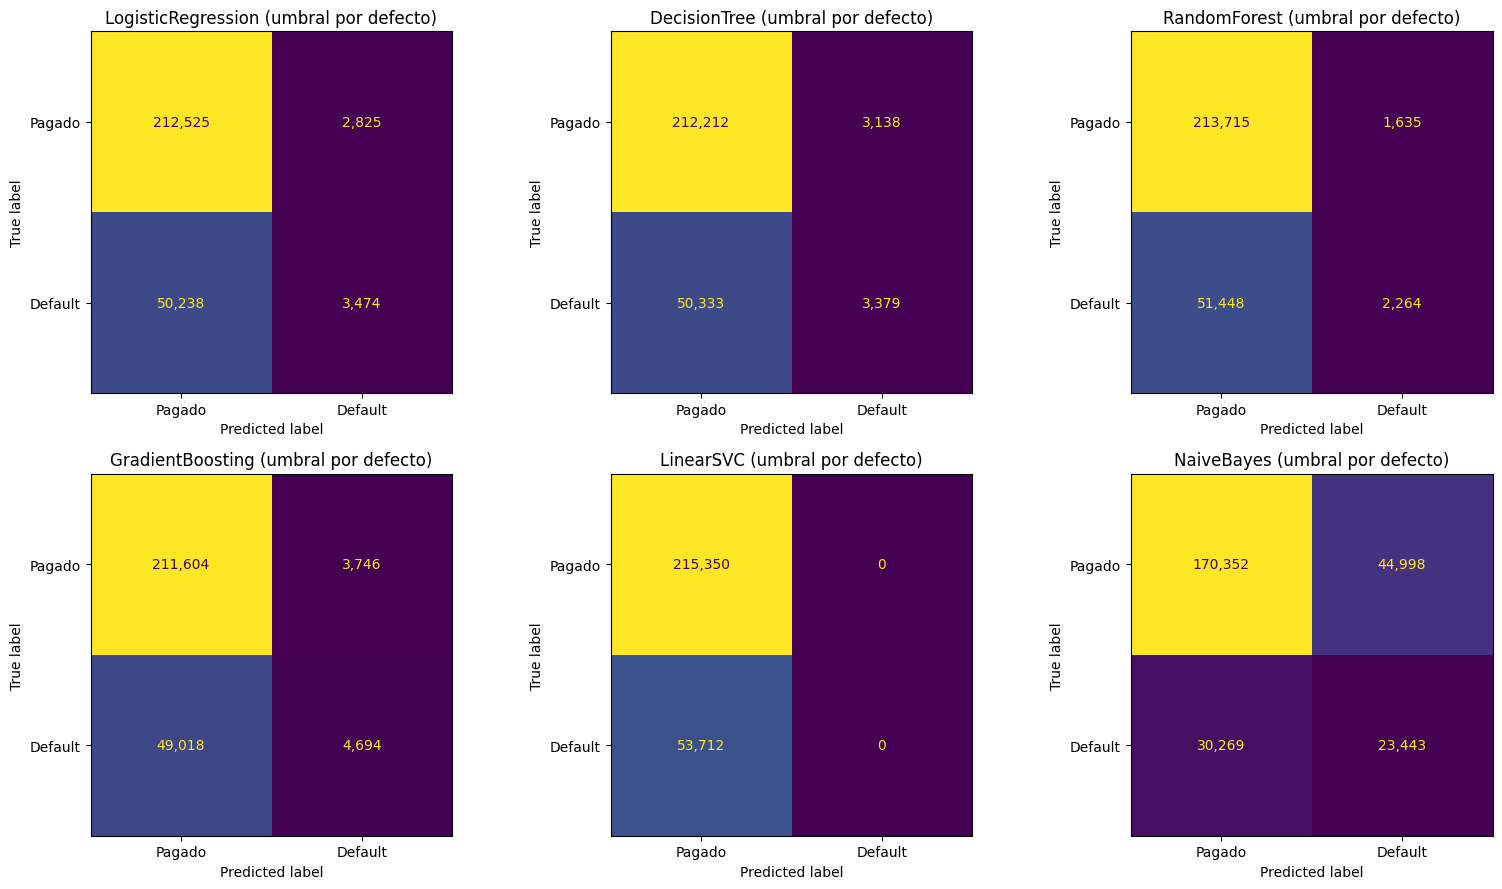

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))  # Una matriz de confusión por modelo
for ax, (nombre, r) in zip(axes.ravel(), resultados.items()):  # Recorre los modelos
    ConfusionMatrixDisplay(np.array(r["metricas"]["matriz_confusion"]), display_labels=["Pagado", "Default"]).plot(ax=ax, colorbar=False, values_format=",")  # Dibuja la matriz
    ax.set_title(f"{nombre} (umbral por defecto)")  # Título
fig.tight_layout()  # Ajusta márgenes
guardar_figura(fig, "04_matrices_confusion_pyspark")  # Exporta la figura
plt.show()  # Muestra la figura

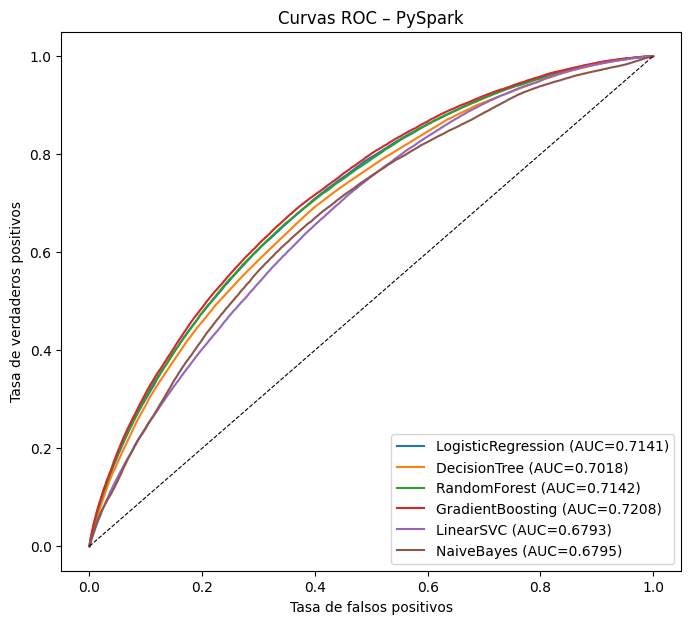

In [11]:
fig, ax = plt.subplots(figsize=(8, 7))  # Curvas ROC de los seis modelos
for nombre in [m for m in cfg.NOMBRES_MODELOS if m in resultados]:  # Recorre los modelos en orden canónico
    s = pd.read_parquet(cfg.DIR_SCORES_SP / f"{nombre}.parquet")  # Puntuaciones transferidas (id, default, score)
    fpr, tpr, _ = roc_curve(s[cfg.COL_TARGET], s["score"])  # Curva ROC
    ax.plot(fpr, tpr, label=f"{nombre} (AUC={resultados[nombre]['metricas']['roc_auc']:.4f})")  # Dibuja la curva
ax.plot([0, 1], [0, 1], "k--", lw=0.8)  # Diagonal de referencia
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos")  # Ejes
ax.set_title("Curvas ROC – PySpark"); ax.legend(loc="lower right")  # Título y leyenda
guardar_figura(fig, "04_roc_pyspark")  # Exporta la figura
plt.show()  # Muestra la figura

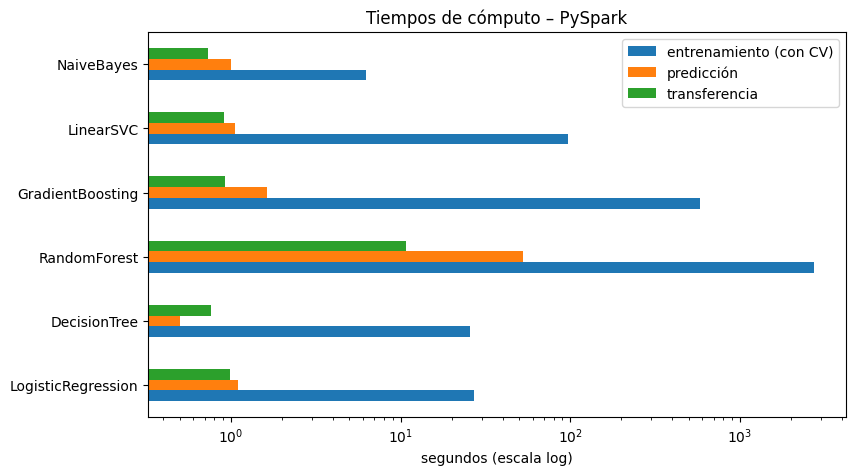

,entrenamiento (con CV),predicción,transferencia
LogisticRegression,27.073861,1.097751,0.982955
DecisionTree,25.515612,0.501452,0.766742
RandomForest,2740.532909,52.799507,10.755929
GradientBoosting,580.838081,1.622343,0.919180
LinearSVC,97.362244,1.056653,0.906327
NaiveBayes,6.260258,0.996200,0.736438


In [12]:
tiempos = pd.DataFrame({n: {"entrenamiento (con CV)": r["tiempo_entrenamiento_s"], "predicción": r["tiempo_prediccion_s"],  # Tiempos por modelo
                            "transferencia": r["tiempo_transferencia_s"]} for n, r in resultados.items()}).T  # Incluye la transferencia
ax = tiempos.plot.barh(figsize=(9, 5), logx=True)  # Barras en escala logarítmica
ax.set_xlabel("segundos (escala log)"); ax.set_title("Tiempos de cómputo – PySpark")  # Ejes y título
plt.show()  # Muestra la figura
tiempos  # Tabla de tiempos

## LIME sobre el mejor modelo de PySpark (en esta misma sesión)

LIME trabaja en memoria local con arreglos de NumPy, pero el modelo de PySpark vive en la
JVM de esta sesión. En Windows sin `winutils`, Spark no puede guardar modelos en disco, y
reajustar el modelo en otra sesión no reproduce exactamente el elegido por el
`CrossValidator`. Por eso la explicación del modelo de PySpark se genera **aquí**, mientras
el modelo sigue vivo. El notebook 06 carga estas explicaciones y las compara con las de
scikit-learn sobre las **mismas instancias y las mismas perturbaciones**.

Cada llamada de LIME (2.000 perturbaciones) se escribe en un Parquet temporal y se lee con
Spark: crear el DataFrame directamente desde pandas sin Arrow tardaba ≈ 250 s por llamada en
Windows (un proceso de Python por partición), frente a menos de un segundo con Parquet.

In [13]:
from src import lime_utils  # Utilidades de LIME compartidas con el notebook 06
from src.utilidades import leer_json  # Lectura de las métricas de scikit-learn

espacio = lime_utils.EspacioLime()  # Datos en el espacio original y conversiones
met_sk = leer_json(cfg.RUTA_METRICAS_SK)["modelos"]  # Métricas de scikit-learn (notebook 03)
mejor_sk = lime_utils.mejor_probabilistico(met_sk)  # Mejor modelo probabilístico de scikit-learn
mejor_sp = lime_utils.mejor_probabilistico(resultados)  # Mejor modelo probabilístico de PySpark
modelo_sp = modelo_lime  # Modelo ganador del CrossValidator del mejor modelo probabilístico (vivo en la sesión)
ruta_tmp = str(cfg.DIR_DATOS / "lime_perturbaciones.parquet")  # Archivo temporal de perturbaciones
llamadas = []  # Tiempo de cada llamada de LIME a Spark


def predecir_sp(X):  # Función de predicción que LIME llamará con cada lote de perturbaciones
    t0 = time.time()  # Inicio de la llamada
    d = espacio.desde_lime(X)  # Perturbaciones en el espacio original (pandas, en el driver)
    d["_orden"] = np.arange(len(d))  # Orden para reconstruir el resultado
    d.to_parquet(ruta_tmp, index=False)  # Se escriben en Parquet (los NaN quedan como nulos)
    sdf = spark.read.parquet(ruta_tmp)  # Spark lee las perturbaciones
    for c in cfg.NUMERICAS_MODELO:  # Asegura tipo double en las numéricas
        sdf = sdf.withColumn(c, F.col(c).cast("double"))  # Conversión de tipo
    sdf = prep_sp.agrupar_categorias(prep_sp.transformar_numericas(sdf), frecuentes)  # Mismas reglas que en train
    pred = modelo_sp.transform(modelo_prep.transform(sdf))  # Preprocesamiento + modelo en Spark
    p1 = pred.select("_orden", vector_to_array("probability")[1].alias("p1")).toPandas().sort_values("_orden")["p1"].to_numpy()  # Solo las perturbaciones vuelven al driver
    llamadas.append(time.time() - t0)  # Registra el tiempo de la llamada
    return np.column_stack([1 - p1, p1])  # Probabilidades [P(0), P(1)]


verif = predecir_sp(espacio.a_lime(espacio.test.iloc[:2000]))[:, 1]  # Verificación sobre 2.000 filas de test
guardadas = pd.read_parquet(cfg.DIR_SCORES_SP / f"{mejor_sp}.parquet").set_index(cfg.COL_ID).loc[espacio.test[cfg.COL_ID].iloc[:2000], "score"].to_numpy()  # Puntuaciones del modelo
print(f"{mejor_sp}: máx. diferencia entre predecir_sp y las puntuaciones guardadas = {np.abs(verif - guardadas).max():.2e}")  # ≈ 0 (salvo nulos imputados)

GradientBoosting: máx. diferencia entre predecir_sp y las puntuaciones guardadas = 0.00e+00


Mejor sklearn: GradientBoosting | mejor PySpark: GradientBoosting | FN comunes: 18,480 | FP comunes: 62,896 | instancias: {'Falso negativo': 101230150, 'Falso positivo': 2826869}


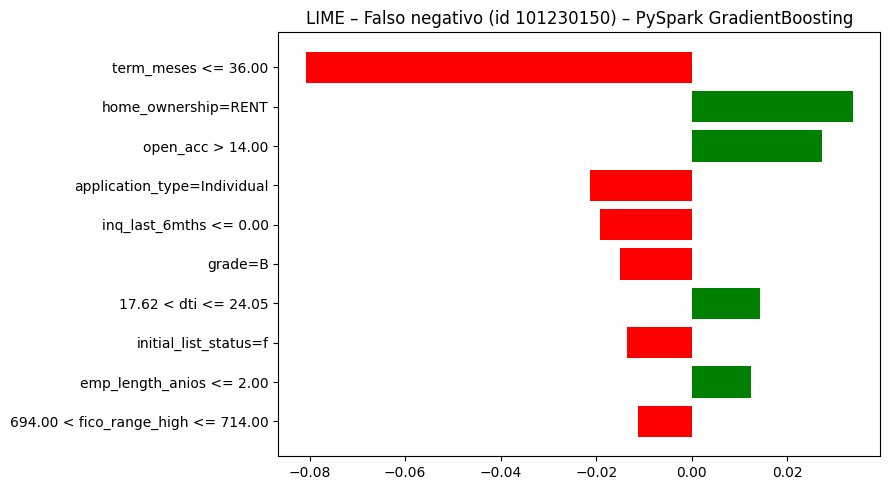

Falso negativo: P(default)=0.140  R² local=0.195  tiempo=4.0s


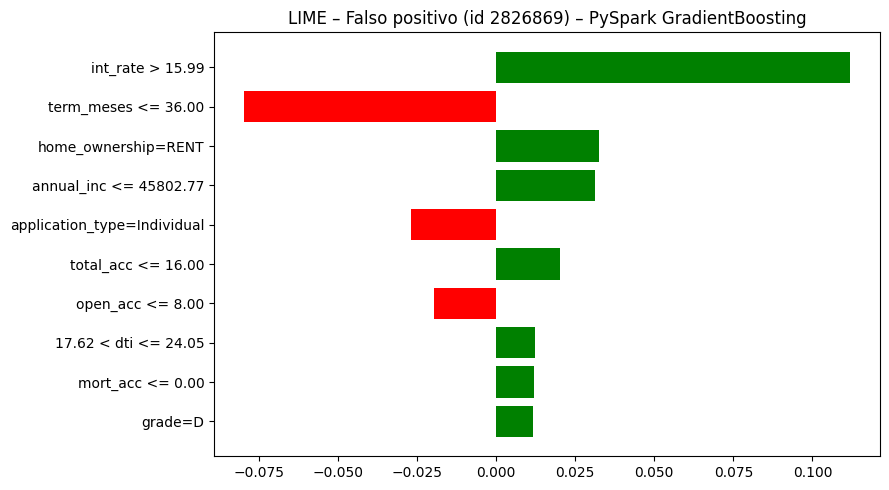

Falso positivo: P(default)=0.299  R² local=0.442  tiempo=3.9s
Llamadas a Spark: 3 | tiempo medio por llamada: 0.57 s


In [14]:
s_sk = pd.read_parquet(cfg.DIR_SCORES_SK / f"{mejor_sk}.parquet").set_index(cfg.COL_ID)["score"]  # Puntuaciones de scikit-learn
s_sp = pd.read_parquet(cfg.DIR_SCORES_SP / f"{mejor_sp}.parquet").set_index(cfg.COL_ID)["score"]  # Puntuaciones de PySpark
instancias, n_fn, n_fp = lime_utils.seleccionar_instancias(espacio.test, s_sk, s_sp, met_sk[mejor_sk]["umbral"], resultados[mejor_sp]["umbral"])  # Instancias mal clasificadas por ambos
print(f"Mejor sklearn: {mejor_sk} | mejor PySpark: {mejor_sp} | FN comunes: {n_fn:,} | FP comunes: {n_fp:,} | instancias: {instancias}")  # Resumen
explicaciones_sp = {}  # Resultados serializables
for etiqueta, id_ in instancias.items():  # Recorre las dos instancias
    t0 = time.time()  # Inicio de la explicación
    exp = espacio.explicador().explain_instance(espacio.instancia(id_), predecir_sp, num_features=lime_utils.N_VARIABLES, num_samples=lime_utils.N_MUESTRAS)  # Explicación local
    explicaciones_sp[etiqueta] = {"id": id_, "pesos": exp.as_list(label=1), "p_default": float(exp.predict_proba[1]),  # Pesos y probabilidad
                                  "r2_local": float(exp.score), "intercepto": float(exp.intercept[1]), "tiempo_s": time.time() - t0}  # Calidad y tiempo
    fig = exp.as_pyplot_figure(label=1); fig.set_size_inches(9, 5)  # Gráfico de pesos hacia "Charged Off"
    plt.title(f"LIME – {etiqueta} (id {id_}) – PySpark {mejor_sp}"); plt.tight_layout()  # Título
    guardar_figura(fig, f"04_lime_{etiqueta.replace(' ', '_')}_pyspark"); plt.show()  # Exporta y muestra
    print(f"{etiqueta}: P(default)={exp.predict_proba[1]:.3f}  R² local={exp.score:.3f}  tiempo={time.time() - t0:.1f}s")  # Resumen
guardar_json({"mejor_sklearn": mejor_sk, "mejor_pyspark": mejor_sp, "instancias": instancias, "n_fn_comunes": n_fn, "n_fp_comunes": n_fp,  # Metadatos
              "explicaciones": explicaciones_sp, "tiempo_medio_llamada_s": float(np.mean(llamadas)), "n_llamadas": len(llamadas)},  # Explicaciones y tiempos
             lime_utils.RUTA_EXPLICACIONES_SP)  # Archivo leído por el notebook 06
print(f"Llamadas a Spark: {len(llamadas)} | tiempo medio por llamada: {np.mean(llamadas):.2f} s")  # Costo de cada llamada

In [15]:
train.unpersist(); test.unpersist()  # Libera la caché de los conjuntos
spark.stop()  # Detiene la sesión de Spark

## Interpretación de los resultados de PySpark

**Capacidad discriminante.** Los AUC son prácticamente los de scikit-learn: *gradient
boosting* 0,7208 (vs 0,7207), regresión logística 0,7141 (vs 0,7141), bosque 0,7142 (vs 0,7153),
árbol 0,7018 (vs 0,7043) y Naive Bayes 0,6795 (vs 0,6792). La gran excepción es LinearSVC: 0,6793
frente a 0,5293. El notebook 05 contrasta formalmente estas diferencias.

**Hiperparámetros.** Se eligen los mismos que en scikit-learn para el árbol (profundidad 10), el
bosque (100 × 15) y el boosting (100 × 5). En la regresión logística los tres `regParam` dan el
mismo AUC de validación hasta el cuarto decimal (0,7139); el elegido (1e-5) y el de scikit-learn
(C ≈ 0,0093 ↔ 1e-4) son, en la práctica, equivalentes.

**Diferencias atribuibles a la implementación.**
* *Árbol de profundidad 5*: 0,654 en CV frente a 0,692 en scikit-learn. Spark **poda las hojas
  hermanas que predicen la misma clase**; con 20 % de defaults, a poca profundidad casi todas
  las hojas predicen "pagado", se fusionan y se pierde la ordenación por probabilidad. A mayor
  profundidad el efecto se diluye (profundidad 10: 0,701 vs 0,696).
* `maxBins = 32`: cada variable continua solo admite 31 cortes candidatos (scikit-learn evalúa
  todos los cortes exactos). Explica pequeñas pérdidas en árbol y bosque (−0,0025 y −0,0011 de AUC).
* *LinearSVC*: con el umbral por defecto (margen 0) no predice ningún default (precisión y recall
  = 0), pero su margen **sí ordena** el riesgo (AUC 0,68): Spark optimiza la pérdida *hinge*
  con OWL-QN, estandariza internamente y no penaliza el intercepto.

**Tiempos (6 hilos en PySpark frente a 12 en scikit-learn).** PySpark fue más rápido en la
regresión logística (27 s vs 63 s), el árbol (26 s vs 37 s) y, sobre todo, LinearSVC (97 s vs
3.549 s), y más lento en el bosque (2.741 s vs 519 s; ×5,3), el boosting (581 s vs 71 s; ×8,2)
y Naive Bayes (6 s vs 4 s). La predicción en Spark cuesta ≈ 1 s por modelo (53 s en el bosque)
por la planificación de trabajos, y la transferencia de `id`, `default` y `score` al driver,
≈ 1 s (11 s en el bosque). El preprocesamiento completo tomó 38 s (vs 29 s en scikit-learn).

**LIME.** La explicación del modelo de PySpark se hizo con el modelo vivo en esta sesión; la
función de predicción reproduce exactamente las puntuaciones guardadas (diferencia máxima 0) y
cada llamada con 2.000 perturbaciones cuesta ≈ 0,6 s gracias al paso por Parquet.